# 20 — Week 5 completion: one validation table, costs, accuracy vs trainable parameters, plan checklist

Reads the outputs of notebooks 17–19 and the frozen Week 4 benchmark; trains nothing. Validation only (the test split
stays closed until the end of Week 6). Numbers are provisional until the Week 6 experiments (data fraction, qubits,
noise) are done.

In [1]:
# Cell 1: setup and inputs
import sys, json
from pathlib import Path
import numpy as np
import polars as pl
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
from models import rnn as R

REP = ROOT / "reports" / "week5"
FIG = ROOT / "reports" / "figures" / "week5"
FIG.mkdir(parents=True, exist_ok=True)
need = {"qnn_smoke.json": "17", "qnn_timing.csv": "17", "qnn_val_summary.csv": "18", "qnn_val.json": "18",
        "qrc_val_summary.csv": "19", "qrc_val.json": "19"}
missing = {f: nb for f, nb in need.items() if not (REP / f).exists()}
print("missing inputs:", missing or "none")
assert not missing, "run the notebooks listed above first"
smoke = json.loads((REP / "qnn_smoke.json").read_text())
qv = json.loads((REP / "qnn_val.json").read_text())
qr = json.loads((REP / "qrc_val.json").read_text())
w4 = pl.read_csv(ROOT / "reports" / "week4" / "benchmark_val_week4_all.csv")
qnn = pl.read_csv(REP / "qnn_val_summary.csv")
qrc = pl.read_csv(REP / "qrc_val_summary.csv")
cost = pl.read_csv(ROOT / "reports" / "week4" / "cost_networks.csv")

missing inputs: none


In [2]:
# Cell 2: one validation table (Week 4 benchmark + hybrid QNN family + QRC family), with trainable parameters
cols = w4.columns
bench = pl.concat([w4,
                   qnn.with_columns(pl.lit(False).alias("covariates")).select(cols).with_columns([pl.col(c).cast(w4.schema[c]) for c in cols]),
                   qrc.with_columns(pl.lit(False).alias("covariates")).select(cols).with_columns([pl.col(c).cast(w4.schema[c]) for c in cols])])
params = pl.concat([cost.group_by("model").agg(pl.col("n_params").first()).select("model", pl.col("n_params").cast(pl.Int64)),
                    qnn.group_by("model").agg(pl.col("n_params").first().cast(pl.Int64)),
                    qrc.group_by("model").agg(pl.col("n_params").first().cast(pl.Int64))])
mid = qnn.group_by("model").agg(pl.col("n_params_middle").first().cast(pl.Int64))
bench = (bench.join(params, on="model", how="left").join(mid, on="model", how="left")
              .sort("h", "MAE_mean").with_columns(pl.col("MAE_mean").rank("ordinal").over("h").alias("rank")))
bench.write_csv(REP / "benchmark_val_week5.csv")
pl.Config.set_tbl_rows(80); pl.Config.set_tbl_cols(20); pl.Config.set_tbl_width_chars(250)
NEW = qnn["model"].unique().to_list() + qrc["model"].unique().to_list()
for h in R.HORIZONS:
    print(f"\n=== h = {h} min, validation ({bench.filter(pl.col('h') == h).height} models; new Week 5 models marked *) ===")
    print(bench.filter((pl.col("h") == h) & (pl.col("model") != "seasonal_naive_1d"))
               .with_columns(pl.when(pl.col("model").is_in(NEW)).then(pl.lit("*")).otherwise(pl.lit("")).alias("new"))
               .select("rank", "new", "family", "model", "n_seeds", pl.col("MAE_mean").round(4), pl.col("MAE_sd").round(4),
                       pl.col("skill_MAE").round(3), pl.col("MAE_ramp").round(3), pl.col("ramp_F1").round(3),
                       "n_params", "n_params_middle"))


=== h = 1 min, validation (28 models; new Week 5 models marked *) ===
shape: (27, 12)
┌──────┬─────┬───────────────────┬─────────────────────────┬─────────┬──────────┬────────┬───────────┬──────────┬─────────┬──────────┬─────────────────┐
│ rank ┆ new ┆ family            ┆ model                   ┆ n_seeds ┆ MAE_mean ┆ MAE_sd ┆ skill_MAE ┆ MAE_ramp ┆ ramp_F1 ┆ n_params ┆ n_params_middle │
│ ---  ┆ --- ┆ ---               ┆ ---                     ┆ ---     ┆ ---      ┆ ---    ┆ ---       ┆ ---      ┆ ---     ┆ ---      ┆ ---             │
│ u32  ┆ str ┆ str               ┆ str                     ┆ i64     ┆ f64      ┆ f64    ┆ f64       ┆ f64      ┆ f64     ┆ i64      ┆ i64             │
╞══════╪═════╪═══════════════════╪═════════════════════════╪═════════╪══════════╪════════╪═══════════╪══════════╪═════════╪══════════╪═════════════════╡
│ 1    ┆     ┆ ML                ┆ lightgbm_cov            ┆ 3       ┆ 0.2464   ┆ 0.0003 ┆ 0.14      ┆ 1.276    ┆ 0.266   ┆ null     ┆ null         

In [3]:
# Cell 3: costs (trainable parameters, training time, time per epoch, inference) for the networks and Week 5 models
qnn_cost = (qnn.group_by("model").agg(pl.col("n_params").first(), pl.col("n_params_middle").first(), pl.col("train_s").first(),
                                      pl.col("s_per_epoch").first(), pl.col("best_epoch").first(),
                                      pl.col("infer_ms_per_sample").first())
               .with_columns(pl.lit("week5_qnn").alias("group"), pl.lit("power only").alias("inputs"), pl.lit("cpu").alias("device")))
qrc_cost = (qrc.group_by("model").agg(pl.col("n_params").first(), (pl.col("reservoir_s").first() + pl.col("readout_s").first()).alias("train_s"))
               .with_columns(pl.lit("week5_qrc").alias("group"), pl.lit("power only").alias("inputs"), pl.lit("cpu").alias("device")))
costs = pl.concat([cost.with_columns(pl.lit(None, pl.Int64).alias("n_params_middle")), qnn_cost, qrc_cost], how="diagonal_relaxed")
costs = costs.select("group", "model", "inputs", "device", "n_params", "n_params_middle", pl.col("train_s").round(0),
                     pl.col("s_per_epoch").round(1), pl.col("best_epoch").round(1), pl.col("infer_ms_per_sample").round(4)).sort("n_params")
costs.write_csv(REP / "cost_week5.csv")
print(costs)
print("\nQRC train_s = reservoir states for all minutes + ridge readout (kernel aggregation not timed); "
      "QNN train_s = full training on CPU with early stopping. Devices differ: times are indicative only.")

shape: (16, 10)
┌───────────┬─────────────────────────┬──────────────────┬────────┬──────────┬─────────────────┬─────────┬─────────────┬────────────┬─────────────────────┐
│ group     ┆ model                   ┆ inputs           ┆ device ┆ n_params ┆ n_params_middle ┆ train_s ┆ s_per_epoch ┆ best_epoch ┆ infer_ms_per_sample │
│ ---       ┆ ---                     ┆ ---              ┆ ---    ┆ ---      ┆ ---             ┆ ---     ┆ ---         ┆ ---        ┆ ---                 │
│ str       ┆ str                     ┆ str              ┆ str    ┆ i64      ┆ i64             ┆ f64     ┆ f64         ┆ f64        ┆ f64                 │
╞═══════════╪═════════════════════════╪══════════════════╪════════╪══════════╪═════════════════╪═════════╪═════════════╪════════════╪═════════════════════╡
│ week5_qrc ┆ ctrl_raw_q8             ┆ power only       ┆ cpu    ┆ 99       ┆ null            ┆ 0.0     ┆ null        ┆ null       ┆ null                │
│ week5_qnn ┆ ctrl_bottleneck_q4_l2   ┆ power on

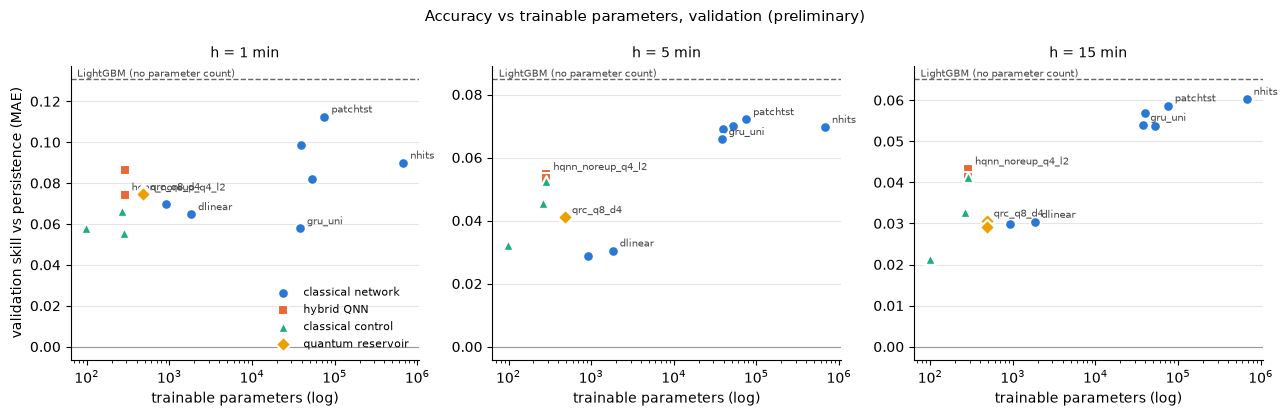

In [4]:
# Cell 4: figure, validation skill vs trainable parameters (log scale), one panel per horizon (preliminary;
# the Week 6 data-fraction and qubit sweeps extend it). LightGBM and persistence as horizontal references.
GROUPS = [("classical network", "#2a78d6", "o"), ("hybrid QNN", "#eb6834", "s"),
          ("classical control", "#1baf7a", "^"), ("quantum reservoir", "#eda100", "D")]
def group_of(row):
    m = row["model"]
    if m.startswith("hqnn"):
        return "hybrid QNN"
    if m.startswith("qrc"):
        return "quantum reservoir"
    if m.startswith("ctrl"):
        return "classical control"
    return "classical network" if row["family"] == "deep" else None
pts = bench.filter(pl.col("n_params").is_not_null()).to_dicts()
fig, axes = plt.subplots(1, 3, figsize=(13, 4.2), sharey=False)
MAIN_Q = qv.get("main_hybrid", {})
main_hqnn = ("hqnn" + ("" if MAIN_Q.get("reupload", True) else "_noreup") +
             f"_q{MAIN_Q.get('n_qubits', 4)}_l{MAIN_Q.get('n_layers', 2)}") if MAIN_Q else None
main_qrc = [m for m in qrc["model"].unique().to_list() if m.startswith("qrc_q")]
LABEL = {"patchtst", "gru_uni", "nhits", "dlinear", main_hqnn, *main_qrc}     # others identified by the legend
for ax, h in zip(axes, R.HORIZONS):
    for g, col, mk in GROUPS:
        sel = [p for p in pts if p["h"] == h and group_of(p) == g]
        if not sel:
            continue
        ax.scatter([p["n_params"] for p in sel], [p["skill_MAE"] for p in sel], s=60, color=col, marker=mk,
                   edgecolor="white", linewidth=1.5, label=g, zorder=3)
        for p in sel:
            if p["model"] in LABEL:
                ax.annotate(p["model"], (p["n_params"], p["skill_MAE"]), xytext=(5, 3), textcoords="offset points",
                            fontsize=7, color="#444444")
    lg = bench.filter((pl.col("h") == h) & (pl.col("model") == "lightgbm"))
    if lg.height:
        ax.axhline(lg["skill_MAE"][0], color="#666666", lw=1, ls="--")
        ax.text(0.01, lg["skill_MAE"][0], " LightGBM (no parameter count)", transform=ax.get_yaxis_transform(),
                va="bottom", fontsize=7, color="#444444")
    ax.axhline(0, color="#999999", lw=0.8)
    ax.set_xscale("log")
    ax.set_title(f"h = {h} min", fontsize=10)
    ax.set_xlabel("trainable parameters (log)")
    ax.grid(axis="y", color="#e5e5e5", lw=0.8)
    for s_ in ("top", "right"):
        ax.spines[s_].set_visible(False)
axes[0].set_ylabel("validation skill vs persistence (MAE)")
axes[0].legend(frameon=False, fontsize=8, loc="lower right")
fig.suptitle("Accuracy vs trainable parameters, validation (preliminary)", fontsize=11)
fig.tight_layout()
fig.savefig(FIG / "02_skill_vs_params_val.png", dpi=150)
plt.show()

In [5]:
# Cell 5: Week 5 checklist from the plan (Project_Context_FA.txt, Section 8, Week 5)
exp = ROOT / "experiments"
qnn_runs = list(exp.glob("week5_qnn*/hqnn*_s*/metrics.json"))
ctrl_runs = list(exp.glob("week5_qnn*/ctrl_mlp*_s*/metrics.json"))
qrc_runs = list((exp / "week5_qrc").glob("qrc_q*_s*/metrics.json"))
ofit = smoke.get("overfit_1pct", [])
main_name = None
for r in qv.get("val_summary", []):
    if r["model"].startswith("hqnn") and "noent" not in r["model"]:
        main_name = r["model"]
items = [
    ("[main] hybrid QNN (encoder -> circuit -> decoder, re-uploading, entangling layers, Z readout)", len(qnn_runs) > 0),
    ("[main] classical control with matched parameter count (same encoder/decoder)", len(ctrl_runs) > 0),
    ("[main] quantum reservoir computing with ridge readout (+ raw, random-feature and no-entanglement controls)", len(qrc_runs) > 0),
    ("[supp] quantum kernel ridge regression on a small subsample", False),
    ("[main] epoch time measured and trainable sample size decided", (REP / "qnn_timing.csv").exists() and (REP / "qrc_timing.csv").exists()),
    ("[main] overfit sanity check (1% check of nb 17 or memorisation check of nb 18)",
     (bool(ofit) and all(o["check"] == "PASS" for o in ofit if o["variant"].startswith(("hqnn", "ctrl_mlp"))))
     or bool(qv.get("memorise_64", {}).get("passed"))),
    ("[main] models connected to the shared evaluation module (src/evaluation/metrics.py)", len(qnn_runs) > 0 and len(qrc_runs) > 0),
    ("[criterion] two main models end-to-end and in the unified table", (REP / "benchmark_val_week5.csv").exists()
     and bench.filter(pl.col("model").str.starts_with("hqnn")).height > 0 and bench.filter(pl.col("model").str.starts_with("qrc")).height > 0),
]
for text, ok in items:
    print(("DONE  " if ok else "OPEN  ") + text)
print(f"\nmain hybrid QNN: {main_name} | decision point (> ~10 min per epoch): "
      f"{'not reached' if smoke['timing']['max_train_samples'] is None else 'reached, subsample used'} "
      f"(slowest grid point {smoke['timing']['worst_epoch_min_full_train']:.1f} min)")
main_done = all(ok for t, ok in items if not t.startswith("[supp]"))
print("ALL MAIN WEEK 5 ITEMS DONE (technical); documents (Methods draft notes, weekly report) still to write"
      if main_done else "some main items are open")
_ = (REP / "week5_completion.json").write_text(json.dumps({"items": [{"item": t, "done": ok} for t, ok in items],
                                                       "main_hybrid": main_name, "all_main_done": main_done}, indent=1))

DONE  [main] hybrid QNN (encoder -> circuit -> decoder, re-uploading, entangling layers, Z readout)
DONE  [main] classical control with matched parameter count (same encoder/decoder)
DONE  [main] quantum reservoir computing with ridge readout (+ raw, random-feature and no-entanglement controls)
OPEN  [supp] quantum kernel ridge regression on a small subsample
DONE  [main] epoch time measured and trainable sample size decided
DONE  [main] overfit sanity check (1% check of nb 17 or memorisation check of nb 18)
DONE  [main] models connected to the shared evaluation module (src/evaluation/metrics.py)
DONE  [criterion] two main models end-to-end and in the unified table

main hybrid QNN: hqnn_noreup_q4_l2 | decision point (> ~10 min per epoch): not reached (slowest grid point 2.3 min)
ALL MAIN WEEK 5 ITEMS DONE (technical); documents (Methods draft notes, weekly report) still to write


In [7]:
# Cell 6: export outputs (save the notebook first with Cmd+S, then run this cell)
%run ../src/tools/nb_outputs_to_md.py 20_week5_completion.ipynb

written 20_week5_completion_outputs.md | code cells 6 | figures 1 in 20_week5_completion_outputs_figures
